# 6.1 PCA (주성분 분석) - 주석 설명판

원본 `6_1.ipynb`의 코드에 설명 주석을 단 버전이에요.

**차원 축소가 왜 필요할까?**
피처(열)가 많으면 데이터가 공간에 듬성듬성 흩어져서 모델이 학습하기 어려워지고(차원의 저주), 비슷한 피처끼리 겹치는 정보(다중공선성)도 생겨요.
→ 피처 여러 개를 **정보를 최대한 살린 채 적은 수의 새 피처로 압축**하는 게 차원 축소예요.

**PCA(Principal Component Analysis)의 아이디어**
- 데이터가 **가장 넓게 퍼진 방향(분산이 가장 큰 방향)** 을 찾아서 그 방향을 첫 번째 축(PC1)으로 잡아요.
- 두 번째 축(PC2)은 PC1과 **직각(직교)** 이면서 그다음으로 분산이 큰 방향이에요.
- 원래 데이터를 이 새 축들 위로 투영(projection)하면 → 차원이 줄어든 데이터가 돼요.
- 수학적으로는 **공분산 행렬의 고유벡터** = 주성분 방향, **고유값** = 그 방향의 분산 크기.

| 용어 | 의미 |
|---|---|
| 주성분 (component) | 새로 만든 축. 원래 피처들의 선형 결합 |
| `explained_variance_ratio_` | 각 주성분이 원래 데이터 분산(정보)의 몇 %를 설명하는지 |
| `n_components` | 몇 개의 주성분으로 줄일지 |

**⚠ PCA 전에는 꼭 스케일링!**
PCA는 분산 크기를 기준으로 축을 찾기 때문에, 단위가 큰 피처(예: 금액)가 있으면 그 피처 쪽으로 축이 쏠려요. → `StandardScaler`로 먼저 평균 0, 분산 1로 맞춰요.

## 1. 붓꽃 데이터 불러오기

In [1]:
from sklearn.datasets import load_iris
import pandas as pd
import matplotlib.pyplot as plt

iris = load_iris()

# 피처 4개: 꽃받침 길이/너비, 꽃잎 길이/너비
# (원본은 'patal_length' 오타 → 'petal_length'로 수정)
columns = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
df = pd.DataFrame(iris.data, columns=columns)
df['target'] = iris.target   # 0: setosa, 1: versicolor, 2: virginica
df.head()

,sepal_length,sepal_width,petal_length,petal_width,target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


## 2. 원본 피처 2개로 시각화

4차원 데이터는 그대로 그릴 수 없어서, 일단 꽃받침 길이/너비 2개만 골라 산점도를 그려 봐요.

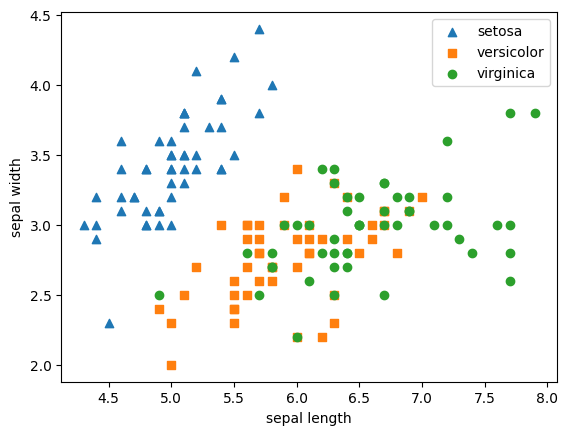

In [2]:
markers = ['^', 's', 'o']   # 품종별 마커: 세모, 네모, 동그라미

# i: 품종 번호(0,1,2) / marker: 그 품종의 마커
for i, marker in enumerate(markers):
    # i번 품종인 행만 골라서 x, y 값 꺼내기
    x_axis_data = df[df['target'] == i]['sepal_length']
    y_axis_data = df[df['target'] == i]['sepal_width']
    plt.scatter(x_axis_data, y_axis_data, marker=marker,
                label=iris.target_names[i])

plt.legend()
plt.xlabel('sepal length')
plt.ylabel('sepal width')
plt.show()

# → setosa는 잘 떨어져 있지만 versicolor와 virginica는 많이 섞여 있음
#   (피처 2개만 골라 쓰면 나머지 2개의 정보는 버려지기 때문)

## 3. 스케일링 → PCA로 4차원을 2차원으로 압축

In [3]:
from sklearn.preprocessing import StandardScaler

# target 열을 뺀 피처 4개만 표준화 (평균 0, 분산 1)
iris_scaled = StandardScaler().fit_transform(df.iloc[:, :-1])

In [4]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)   # 주성분 2개로 줄이기

pca.fit(iris_scaled)                     # fit: 주성분 방향(축) 찾기
iris_pca = pca.transform(iris_scaled)    # transform: 데이터를 새 축 위로 투영
print(iris_pca.shape)   # (150, 2) → 150개 데이터, 피처 4개 → 2개

# (참고) fit + transform을 한 번에: pca.fit_transform(iris_scaled)

(150, 2)


In [5]:
# PCA 결과(넘파이 배열)를 보기 좋게 DataFrame으로
pca_columns = ['pca_component_1', 'pca_component_2']
df_pca = pd.DataFrame(iris_pca, columns=pca_columns)
df_pca['target'] = iris.target
df_pca.head()

# ⚠ pca_component_1은 '원래 피처 하나'가 아니라 피처 4개를 섞어서 만든 새 값이에요.
#   그래서 '길이'처럼 직관적인 의미는 없어요.

,pca_component_1,pca_component_2,target
0,-2.264703,0.480027,0
1,-2.080961,-0.674134,0
2,-2.364229,-0.341908,0
3,-2.299384,-0.597395,0
4,-2.389842,0.646835,0


## 4. PCA 결과 시각화

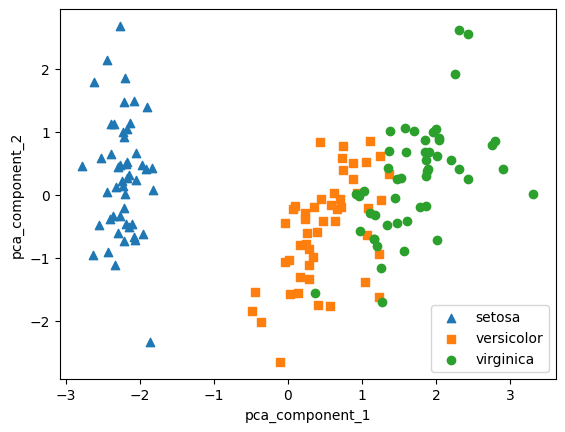

In [6]:
markers = ['^', 's', 'o']

# 2번 그래프와 같은 코드, x/y만 주성분 1, 2로 바꿈
for i, marker in enumerate(markers):
    x_axis_data = df_pca[df_pca['target'] == i]['pca_component_1']
    y_axis_data = df_pca[df_pca['target'] == i]['pca_component_2']
    plt.scatter(x_axis_data, y_axis_data, marker=marker,
                label=iris.target_names[i])

plt.legend()
plt.xlabel('pca_component_1')
plt.ylabel('pca_component_2')
plt.show()

# → 2번 그래프보다 품종이 훨씬 잘 나뉨
#   특히 pca_component_1(가로축) 하나만으로도 세 품종이 거의 구분됨

## 5. 각 주성분이 정보를 얼마나 담고 있나?

In [7]:
# 주성분별 설명 분산 비율
print(pca.explained_variance_ratio_)

# 결과: [0.7296 0.2285]
#  PC1 → 원래 데이터 분산의 약 73%
#  PC2 → 약 23%
#  합계 → 약 96%  = 피처 4개를 2개로 줄여도 정보의 96%가 남아 있음

[0.72962445 0.22850762]


## 6. 원본 vs PCA 데이터로 분류 정확도 비교

`cross_val_score`로 교차 검증(cv=3 → 데이터를 3조각으로 나눠 3번 학습/평가) 정확도를 비교해요.

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
import numpy as np

rfc = RandomForestClassifier(random_state=156)

# 원본 피처 4개 그대로 사용
scores = cross_val_score(rfc, iris.data, iris.target, scoring='accuracy', cv=3)

print('원본 데이터 교차 검증 개별 정확도 :', scores)
print('원본 데이터 평균 정확도 :', np.mean(scores))
# 결과: [0.98 0.94 0.96] → 평균 0.96

원본 데이터 교차 검증 개별 정확도 : [0.98 0.94 0.96]
원본 데이터 평균 정확도 : 0.96


In [9]:
# PCA로 줄인 피처 2개만 사용
pca_X = df_pca[['pca_component_1', 'pca_component_2']]
scores_pca = cross_val_score(rfc, pca_X, iris.target, scoring='accuracy', cv=3)  # cv=3: 3-폴드

print('PCA 변환 데이터 교차 검증 개별 정확도 :', scores_pca)
print('PCA 변환 데이터 평균 정확도 :', np.mean(scores_pca))
# 결과: [0.88 0.88 0.88] → 평균 0.88

PCA 변환 데이터 교차 검증 개별 정확도 : [0.88 0.88 0.88]
PCA 변환 데이터 평균 정확도 : 0.88


**결과 해석**

| 데이터 | 피처 수 | 평균 정확도 |
|---|---|---|
| 원본 | 4 | **0.96** |
| PCA 변환 | 2 | 0.88 |

피처를 절반으로 줄였더니 정확도가 약 8%p 떨어졌어요. 정보 4%를 버린 대가예요.
→ PCA는 **정확도를 올리는 도구라기보다 "적은 피처로 비슷한 성능"** 을 내거나, 시각화 / 계산량 감소 / 노이즈 제거에 쓰는 도구예요.

---
## 7. 신용카드 고객 데이터에 PCA 적용

대만 신용카드 고객 30,000명의 데이터로 **다음 달 연체 여부(default)** 를 예측해요.

| 피처 | 의미 |
|---|---|
| `LIMIT_BAL` | 카드 한도 |
| `SEX`, `EDUCATION`, `MARRIAGE`, `AGE` | 인적 정보 |
| `PAY_1` ~ `PAY_6` | 최근 6개월 각 달의 상환 상태 (-1: 정상, 1 이상: 몇 달 연체) |
| `BILL_AMT1` ~ `BILL_AMT6` | 최근 6개월 각 달의 청구 금액 |
| `PAY_AMT1` ~ `PAY_AMT6` | 최근 6개월 각 달의 실제 지불 금액 |

In [10]:
import pandas as pd

# header=1: 엑셀의 두 번째 줄을 열 이름으로 사용 (첫 줄은 X1, X2... 같은 코드라서)
# .iloc[0:, 1:]: 첫 번째 열(ID)은 필요 없으니 제외
df = pd.read_excel('./pca_credit_card.xls', header=1, sheet_name='Data').iloc[0:, 1:]

print(df.shape)   # (30000, 24) → 피처 23개 + 타깃 1개
df.head()

(30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [11]:
# 이름 정리
#  PAY_0 → PAY_1 : 다른 열들(BILL_AMT1, PAY_AMT1)과 번호를 맞추기 위해
#  'default payment next month' → 'default' : 너무 길어서
df.rename(columns={'PAY_0': 'PAY_1', 'default payment next month': 'default'}, inplace=True)

y_target = df['default']                    # 정답 (0: 정상, 1: 연체)
X_features = df.drop('default', axis=1)     # 피처 23개

In [12]:
# 결측치 / 자료형 확인 → 30000개 모두 non-null, 전부 int64
X_features.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 23 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   LIMIT_BAL  30000 non-null  int64
 1   SEX        30000 non-null  int64
 2   EDUCATION  30000 non-null  int64
 3   MARRIAGE   30000 non-null  int64
 4   AGE        30000 non-null  int64
 5   PAY_1      30000 non-null  int64
 6   PAY_2      30000 non-null  int64
 7   PAY_3      30000 non-null  int64
 8   PAY_4      30000 non-null  int64
 9   PAY_5      30000 non-null  int64
 10  PAY_6      30000 non-null  int64
 11  BILL_AMT1  30000 non-null  int64
 12  BILL_AMT2  30000 non-null  int64
 13  BILL_AMT3  30000 non-null  int64
 14  BILL_AMT4  30000 non-null  int64
 15  BILL_AMT5  30000 non-null  int64
 16  BILL_AMT6  30000 non-null  int64
 17  PAY_AMT1   30000 non-null  int64
 18  PAY_AMT2   30000 non-null  int64
 19  PAY_AMT3   30000 non-null  int64
 20  PAY_AMT4   30000 non-null  int64
 21  PAY_AMT5   3

## 8. 피처끼리 상관관계 확인 (히트맵)

<Axes: >

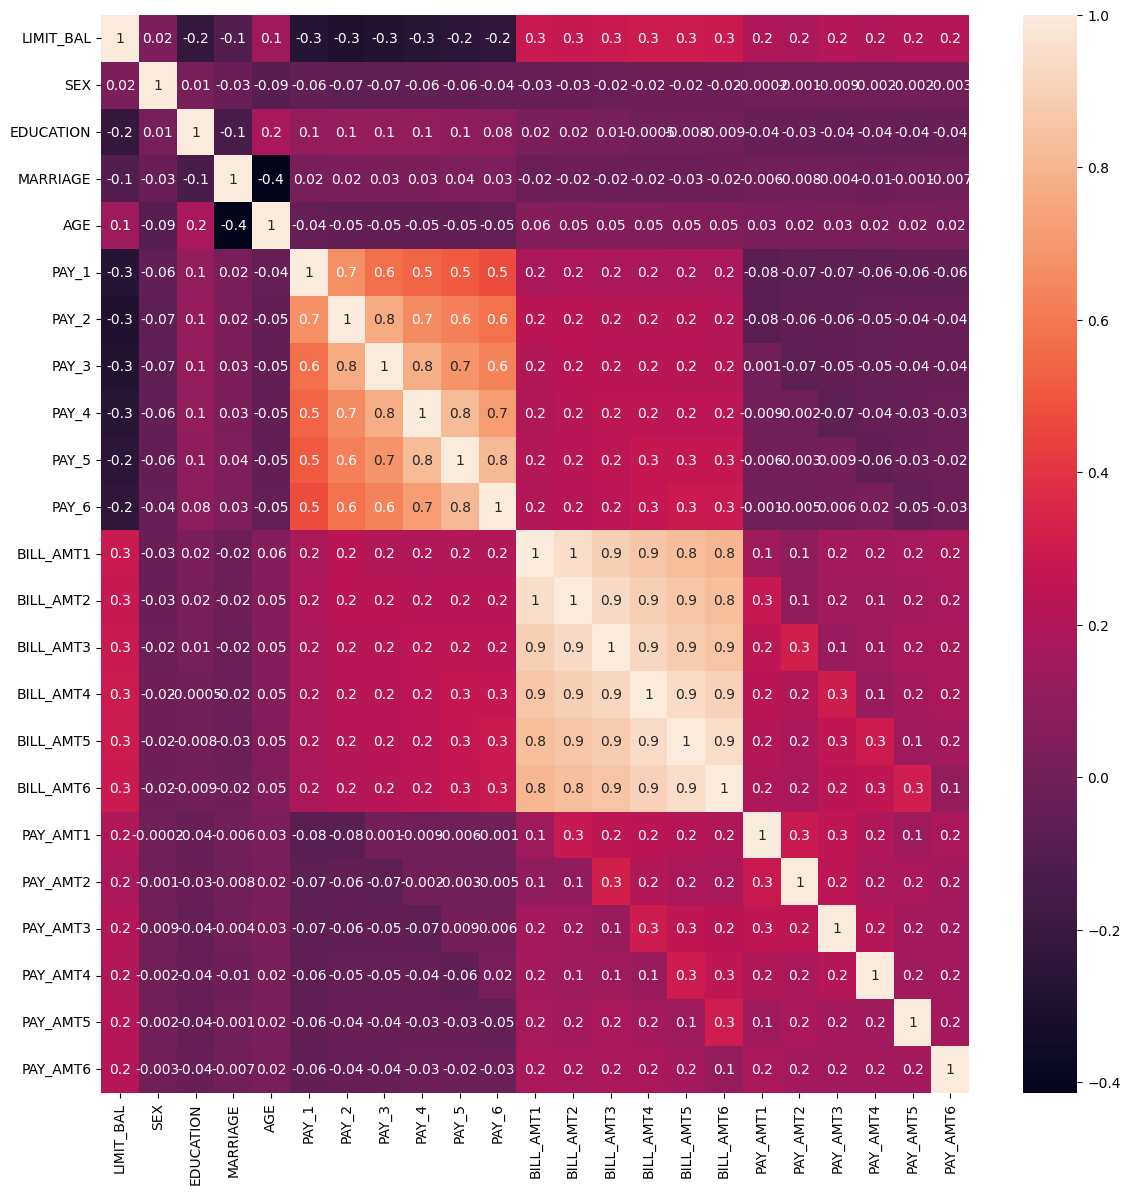

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = X_features.corr()   # 피처 간 상관계수 (-1 ~ 1)
plt.figure(figsize=(14, 14))
# annot=True: 칸에 숫자 표시 / fmt='.1g': 유효숫자 1자리
sns.heatmap(corr, annot=True, fmt='.1g')

# → BILL_AMT1~6 끼리는 상관계수가 0.8~0.9 이상으로 매우 높음 (매달 청구 금액이 비슷하니까)
#   PAY_1~6 끼리도 꽤 높음
#   = 비슷한 정보를 가진 피처가 여러 개 → PCA로 압축하기 좋은 대상

## 9. 상관관계 높은 피처 18개 → PCA 2개로 압축

In [14]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 열 이름 리스트를 반복문으로 만들기
cols_bill = ['BILL_AMT' + str(i) for i in range(1, 7)]   # BILL_AMT1 ~ BILL_AMT6
cols_pay = ['PAY_' + str(i) for i in range(1, 7)]        # PAY_1 ~ PAY_6
cols_amt = ['PAY_AMT' + str(i) for i in range(1, 7)]     # PAY_AMT1 ~ PAY_AMT6

print(cols_bill)
# extend: 리스트 뒤에 다른 리스트의 원소들을 이어 붙임 → cols_bill에 18개가 모임
cols_bill.extend(cols_pay)
cols_bill.extend(cols_amt)
print('대상 속성명: ', cols_bill)

['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6']
대상 속성명:  ['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_1', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']


In [15]:
scaler = StandardScaler()
df_cols_scaled = scaler.fit_transform(X_features[cols_bill])   # 18개 열만 표준화

# 표준화한 값을 X_features에 다시 덮어씀
# (⚠ 그래서 아래 10번의 '원본' 랜덤 포레스트는 18개 열이 스케일링된 상태로 학습돼요.
#     트리 모델은 스케일에 영향을 안 받아서 결과에는 문제없음)
X_features.loc[:, cols_bill] = df_cols_scaled

pca = PCA(n_components=2)
pca.fit(df_cols_scaled)
print('PCA Component 별 변동성: ', pca.explained_variance_ratio_)

# 결과: [0.3618 0.2062] → 합계 약 57%
#  피처 18개를 2개로 줄이면 정보의 57%만 남음
#  (BILL_AMT 6개만 넣으면 서로 상관이 매우 높아서 PC1 하나가 대부분을 설명해요.
#   여기서는 성격이 다른 PAY, PAY_AMT까지 넣어서 비율이 낮아짐)

PCA Component 별 변동성:  [0.36180187 0.20618472]


## 10. 원본 vs PCA 데이터로 연체 예측 정확도 비교

In [16]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

# 트리 300개짜리 랜덤 포레스트
rfc = RandomForestClassifier(n_estimators=300, random_state=156)

# 피처 23개 전부 사용
scores = cross_val_score(rfc, X_features, y_target, scoring='accuracy', cv=3)

print('CV=3 인 경우의 개별 Fold세트별 정확도: ', scores)
print('평균 정확도: ', np.mean(scores))
# 결과: [0.8081 0.8197 0.8232] → 평균 0.817

CV=3 인 경우의 개별 Fold세트별 정확도:  [0.8081 0.8197 0.8232]
평균 정확도:  0.8170000000000001


In [17]:
# 피처 23개 전체를 표준화
scaler = StandardScaler()
df_scaled = scaler.fit_transform(X_features)

# 23개 → 주성분 6개로 압축
pca = PCA(n_components=6)
df_pca = pca.fit_transform(df_scaled)
scores_pca = cross_val_score(rfc, df_pca, y_target, scoring='accuracy', cv=3)

print('PCA 변환 데이터 셋 개별 Fold세트별 정확도: ', scores_pca)
print('PCA 변환 데이터 셋 평균 정확도: ', np.mean(scores_pca))
# 결과: [0.7907 0.7976 0.8021] → 평균 0.797

PCA 변환 데이터 셋 개별 Fold세트별 정확도:  [0.793 0.798 0.803]
PCA 변환 데이터 셋 평균 정확도:  0.798


## 11. 결과 해석

| 데이터 | 피처 수 | 평균 정확도 |
|---|---|---|
| 원본 | 23 | **0.817** |
| PCA 변환 | 6 | 0.797 |

피처를 **약 1/4로 줄였는데도 정확도는 2%p 정도만** 떨어졌어요.

**⚠ 핵심 포인트**
- PCA는 정보를 일부 버리기 때문에 보통 정확도가 **약간 떨어져요**.
- 대신 피처 수가 크게 줄어서 **학습 속도↑, 메모리↓**, 상관관계 높은 피처들의 중복 제거 효과가 있어요.
- 붓꽃(4→2개)보다 신용카드(23→6개)에서 손해가 적었던 이유 → 신용카드 데이터는 **서로 비슷한 피처(BILL_AMT, PAY)가 많아서** 압축해도 잃는 정보가 적었기 때문이에요.
- PCA는 이미지처럼 **피처가 아주 많은 데이터**(픽셀 수천 개)에서 특히 효과가 커요.